# Pneumonia Detection via Inner Residual Inception (SauberModel3)

This notebook implements a custom **Inner Residual Inception** CNN for binary classification of chest X-rays into **NORMAL** vs **PNEUMONIA** using the [Kaggle Chest X-Ray dataset](https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia).

### Key design choices
| Choice | Rationale |
|---|---|
| 4 parallel inception branches | Captures multi-scale features (3×3, 5×5, factorised 3×1+1×3) simultaneously |
| Inner residual shortcut per block | Eases gradient flow; allows deeper stacking without vanishing gradients |
| Global Average Pooling before classifier | Collapses spatial dims (64×64→1×1), removes the need for a huge Linear layer |
| BCEWithLogitsLoss | Numerically stable, AMP-safe replacement for Sigmoid + BCELoss |
| Mixed Precision (AMP) | fp16 on Tensor Cores → ~2× faster, half the VRAM for activations |

## Cell 1 — Imports & CUDA Verification

We import all dependencies and verify that a CUDA-capable GPU is available.  
`torch.backends.cudnn.benchmark = True` tells cuDNN to auto-profile and select the fastest convolution algorithm for each input shape — essential on fixed-size inputs like 64×64.

In [1]:
n_epoch =50
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import sys, os, time

if not torch.cuda.is_available():
    raise RuntimeError(
        f"CUDA not available (torch={torch.__version__}). "
        "Activate the project venv: .venv\\Scripts\\activate"
    )

# Let cuDNN benchmark and pick the fastest conv kernel for each shape
torch.backends.cudnn.benchmark = True

device = torch.device('cuda')
print(f'Device : {torch.cuda.get_device_name(0)}')
print(f'VRAM   : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')
print(f'Torch  : {torch.__version__}')
print(f'epochs  : {n_epoch}')

Device : NVIDIA GeForce RTX 4070 Ti SUPER
VRAM   : 17.2 GB
Torch  : 2.5.1+cu121
epochs  : 50


## Cell 2 — Dataset Download & Verification

The dataset is downloaded from Kaggle using the Kaggle API.  
- If `chest_xray/train` already exists the download **and** extraction are skipped entirely.
- We verify the file counts against the expected split sizes from the paper.

In [2]:
import zipfile, subprocess

os.environ['KAGGLE_USERNAME'] = "amrmsauber"
os.environ['KAGGLE_KEY']      = "KGAT_ceeffe620f713b8e6130fd931de9cb9c"
import kaggle

base_dir  = "chest_xray_ii"
zip_file  = "chest-xray-pneumonia.zip"
slug      = "paultimothymooney/chest-xray-pneumonia"

if not os.path.exists(base_dir):
    os.makedirs(base_dir, exist_ok=True)
    if not os.path.exists(zip_file):
        print("Downloading from Kaggle...")
        subprocess.run(f"kaggle datasets download -d {slug}", shell=True)

if not os.path.exists(os.path.join(base_dir, "train")):
    print("Extracting...")
    with zipfile.ZipFile(zip_file, 'r') as z:
        z.extractall(os.getcwd())
    print("Done.")
else:
    print("Dataset already extracted — skipping.")

train_path = os.path.join(base_dir, 'train')
test_path  = os.path.join(base_dir, 'test')

def count_files(d):
    return sum(len(f) for _, _, f in os.walk(d))

print(f"Train images : {count_files(train_path):,}  (paper: 4,684)")
print(f"Test  images : {count_files(test_path):,}  (paper: 1,172)")

Dataset already extracted — skipping.
Train images : 5,234  (paper: 4,684)
Test  images : 626  (paper: 1,172)


## Cell 3 — Data Preprocessing & DataLoaders

Images are resized to **64×64** (as per the paper) and normalised with ImageNet statistics.

### DataLoader tuning (Windows / Dual-Xeon)
| Parameter | Value | Why |
|---|---|---|
| `batch_size` | 512 | Fills ~17 GB VRAM efficiently |
| `num_workers` | 4 | 4 of 72 cores prefetch images; avoids Windows spawn overhead |
| `persistent_workers` | True | Workers stay alive between epochs — no re-spawn cost |
| `prefetch_factor` | 4 | Each worker buffers 4 batches; GPU never idles waiting for data |

> **Note:** `pin_memory` is intentionally **omitted** — on Windows it adds allocation overhead that outweighs any transfer speedup.

In [3]:
transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

N_WORKERS = 4  # safe for Jupyter on Windows (spawn-based multiprocessing)

train_loader = DataLoader(
    datasets.ImageFolder(train_path, transform=transform),
    batch_size=512, shuffle=True,
    num_workers=N_WORKERS, persistent_workers=True, prefetch_factor=4,
)
test_loader = DataLoader(
    datasets.ImageFolder(test_path, transform=transform),
    batch_size=512, shuffle=False,
    num_workers=N_WORKERS, persistent_workers=True, prefetch_factor=4,
)

print(f"Train batches : {len(train_loader)}")
print(f"Test  batches : {len(test_loader)}")

Train batches : 11
Test  batches : 2


## Cell 4 — Model Architecture

### `InnerResidualBlock`
Each block wraps a convolution with a **residual shortcut**:
```
Input ──► Conv (+ optional factorisation) ──► BN ──► MaxPool(stride=1)
       └──────────────── 1×1 Conv (if shapes differ) ────────────────┘ ⊕ → Output
```
- `MaxPool2d(stride=1, padding=1)` applies a local max but **preserves spatial dimensions** so residuals stay shape-compatible.
- The factorised branch (`is_forth=True`) replaces a 3×3 conv with two cheaper asymmetric convs: 3×1 then 1×3.

### `SauberModel3` — 4-branch Inception
```
             ┌── Branch 1: 3×3 × 3 stacked ──► 96 ch ──┐
Input ► Stem─┤── Branch 2: 5×5 × 3 stacked ──► 32 ch ──┼─► Concat(320ch)
             │── Branch 3: 3×3 × 3 stacked ──►128 ch ──┤    ► 1×1 Conv ► 64 ch
             └── Branch 4: 3×1+1×3 × 3   ──► 64 ch ──┘    ► GAP ──► Linear(64→1)
```
The **outer residual** (`id_outer = stem(x)`) is added before Global Average Pooling, giving the whole inception block a skip connection.

> **`BCEWithLogitsLoss` note:** The final layer outputs raw **logits** (no Sigmoid).  
> `BCEWithLogitsLoss` applies the sigmoid internally in numerically stable float32 — required for AMP compatibility.

In [4]:
class InnerResidualBlock(nn.Module):
    def __init__(self, in_c, out_c, k_size=3, is_forth=False):
        super().__init__()
        if is_forth:  # Factorised branch: 3×1 then 1×3 (cheaper than 3×3)
            self.conv = nn.Sequential(
                nn.Conv2d(in_c, out_c, (3, 1), padding='same'), nn.ReLU(),
                nn.Conv2d(out_c, out_c, (1, 3), padding='same'), nn.ReLU())
        else:
            self.conv = nn.Sequential(
                nn.Conv2d(in_c, out_c, k_size, padding='same'), nn.ReLU())

        self.bn       = nn.BatchNorm2d(out_c)
        # stride=1 MaxPool preserves spatial dims for residual compatibility
        self.pool     = nn.MaxPool2d(2, stride=1, padding=1)
        self.shortcut = nn.Conv2d(in_c, out_c, 1) if in_c != out_c else nn.Identity()

    def forward(self, x):
        res = self.conv(x)
        res = self.pool(res)[:, :, :x.shape[2], :x.shape[3]]  # trim back to original size
        return self.bn(res) + self.shortcut(x)                 # residual add


class SauberModel3(nn.Module):
    def __init__(self):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, 64, 3, padding='same'), nn.ReLU())

        # Four parallel inception branches, each stacked 3× deep
        self.b1 = nn.ModuleList([InnerResidualBlock(64 if i==0 else 96,  96,  3) for i in range(3)])
        self.b2 = nn.ModuleList([InnerResidualBlock(64 if i==0 else 32,  32,  5) for i in range(3)])
        self.b3 = nn.ModuleList([InnerResidualBlock(64 if i==0 else 128, 128, 3) for i in range(3)])
        self.b4 = nn.ModuleList([InnerResidualBlock(64 if i==0 else 64,  64,  is_forth=True) for i in range(3)])

        self.concat_conv = nn.Conv2d(96 + 32 + 128 + 64, 64, 1)  # 320 → 64 ch
        self.dropout     = nn.Dropout(0.3)
        # Global Average Pooling collapses 64×64 spatial map to 1×1
        # → Linear only needs 64 inputs instead of 64×64×64 = 262,144
        self.gap         = nn.AdaptiveAvgPool2d(1)
        # No Sigmoid here — BCEWithLogitsLoss applies it internally (AMP-safe)
        self.classifier  = nn.Sequential(nn.Flatten(), nn.Linear(64, 1))

    def forward(self, x):
        x        = self.stem(x)
        id_outer = x                          # outer residual saved before branches
        out1, out2, out3, out4 = x, x, x, x
        for i in range(3):
            out1, out2, out3, out4 = (
                self.b1[i](out1), self.b2[i](out2),
                self.b3[i](out3), self.b4[i](out4)
            )
        m = torch.cat([out1, out2, out3, out4], dim=1)  # concat all branches
        m = self.dropout(self.concat_conv(m))            # 320 → 64 ch
        m = self.gap(m + id_outer)                       # outer residual + GAP
        return self.classifier(m)                        # raw logits


model = SauberModel3().to(device)
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Model parameters : {n_params:,}")
print(model)

Model parameters : 808,065
SauberModel3(
  (stem): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (1): ReLU()
  )
  (b1): ModuleList(
    (0): InnerResidualBlock(
      (conv): Sequential(
        (0): Conv2d(64, 96, kernel_size=(3, 3), stride=(1, 1), padding=same)
        (1): ReLU()
      )
      (bn): BatchNorm2d(96, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (pool): MaxPool2d(kernel_size=2, stride=1, padding=1, dilation=1, ceil_mode=False)
      (shortcut): Conv2d(64, 96, kernel_size=(1, 1), stride=(1, 1))
    )
    (1-2): 2 x InnerResidualBlock(
      (conv): Sequential(
        (0): Conv2d(96, 96, kernel_size=(3, 3), stride=(1, 1), padding=same)
        (1): ReLU()
      )
      (bn): BatchNorm2d(96, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (pool): MaxPool2d(kernel_size=2, stride=1, padding=1, dilation=1, ceil_mode=False)
      (shortcut): Identity()
    )
  )
  (b2): ModuleList(
    

## Cell 5 — Training Loop (50 Epochs)

### Optimiser & loss
- **Adam** at `lr=3e-4` — well-suited to residual/inception nets.
- **`BCEWithLogitsLoss`** — AMP-safe, numerically stable.

### Mixed Precision (AMP)
```python
with torch.amp.autocast('cuda'):   # forward in float16
    ...
scaler.scale(loss).backward()      # scale gradients to avoid fp16 underflow
scaler.step(optimizer)
scaler.update()                    # adjusts scale factor each step
```

### Other micro-optimisations
| Trick | Saving |
|---|---|
| `zero_grad(set_to_none=True)` | Skips memset on all params; slightly faster than zeroing |
| `imgs.to(device, non_blocking=True)` | Overlaps CPU→GPU DMA with GPU compute |
| Accumulators kept on GPU | Only 1 `.item()` call per batch (for `loss`), not per metric |

In [5]:
#n_epoch = 50
optimizer = optim.Adam(model.parameters(), lr=3e-4)
criterion = nn.BCEWithLogitsLoss()   # AMP-safe: fuses Sigmoid + BCE in float32
scaler    = torch.amp.GradScaler('cuda')

epoch_losses, epoch_accs, epoch_recalls, epoch_times = [], [], [], []
n_batches = len(train_loader)

for epoch in range(n_epoch):
    start_time = time.time()
    model.train()
    running_loss = 0.0

    # Keep accumulators on-device to avoid per-batch host→device sync
    correct          = torch.tensor(0.0, device=device)
    total            = torch.tensor(0.0, device=device)
    true_positives   = torch.tensor(0.0, device=device)
    actual_positives = torch.tensor(0.0, device=device)

    for batch_idx, (imgs, labels) in enumerate(train_loader):
        print(f'  Epoch {epoch+1}/50 | Batch {batch_idx+1}/{n_batches}',
              end='\r', flush=True)

        imgs   = imgs.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True).float().unsqueeze(1)

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast('cuda'):      # float16 forward
            outputs = model(imgs)
            loss    = criterion(outputs, labels)

        scaler.scale(loss).backward()         # scaled fp16 backward
        scaler.step(optimizer)
        scaler.update()

        running_loss     += loss.item()
        # Apply sigmoid to logits for binary predictions
        predictions       = torch.round(torch.sigmoid(outputs.detach()))
        correct          += (predictions == labels).sum()
        total            += labels.size(0)
        true_positives   += ((predictions == 1) & (labels == 1)).sum()
        actual_positives += (labels == 1).sum()

    # Pull metrics to CPU once per epoch
    avg_loss     = running_loss / n_batches
    epoch_acc    = (correct / total).item()
    epoch_recall = (true_positives / (actual_positives + 1e-8)).item()
    epoch_time   = (time.time() - start_time) / 60

    epoch_losses.append(avg_loss)
    epoch_accs.append(epoch_acc)
    epoch_recalls.append(epoch_recall)
    epoch_times.append(epoch_time)

    print(f'Epoch {epoch+1:>2}/50 | Loss: {avg_loss*100:.4f} | '
          f'Acc: {epoch_acc*100:.4f} | Recall: {epoch_recall*100:.4f} | '
          f'Time: {epoch_time:.2f} min', flush=True)

Epoch  1/50 | Loss: 54.8024 | Acc: 70.9289 | Recall: 63.0440 | Time: 11.99 min
Epoch  2/50 | Loss: 31.2233 | Acc: 88.7424 | Recall: 88.6686 | Time: 4.24 min
Epoch  3/50 | Loss: 21.9128 | Acc: 92.1445 | Recall: 94.9524 | Time: 3.98 min
Epoch  4/50 | Loss: 15.7222 | Acc: 94.1514 | Recall: 96.8581 | Time: 3.92 min
Epoch  5/50 | Loss: 12.0776 | Acc: 95.9480 | Recall: 97.8625 | Time: 3.81 min
Epoch  6/50 | Loss: 11.2152 | Acc: 96.6552 | Recall: 98.2745 | Time: 3.84 min
Epoch  7/50 | Loss: 9.2852 | Acc: 96.3876 | Recall: 98.1973 | Time: 3.79 min
Epoch  8/50 | Loss: 8.8094 | Acc: 96.7317 | Recall: 98.0428 | Time: 3.83 min
Epoch  9/50 | Loss: 7.7841 | Acc: 97.1713 | Recall: 98.2230 | Time: 3.86 min
Epoch 10/50 | Loss: 7.0930 | Acc: 97.6300 | Recall: 98.7381 | Time: 3.81 min
Epoch 11/50 | Loss: 6.6970 | Acc: 97.7829 | Recall: 98.8669 | Time: 3.80 min
Epoch 12/50 | Loss: 6.9888 | Acc: 97.8020 | Recall: 98.6866 | Time: 3.81 min
Epoch 13/50 | Loss: 7.3840 | Acc: 97.4962 | Recall: 98.8669 | Time: 3

## Cell 6 — Visualise Training Metrics

Plots **Loss**, **Accuracy**, and **Recall** over 50 epochs.  
For a medical classifier, **Recall** (sensitivity) is the most clinically important metric — a missed pneumonia case (false negative) is more harmful than a false positive.

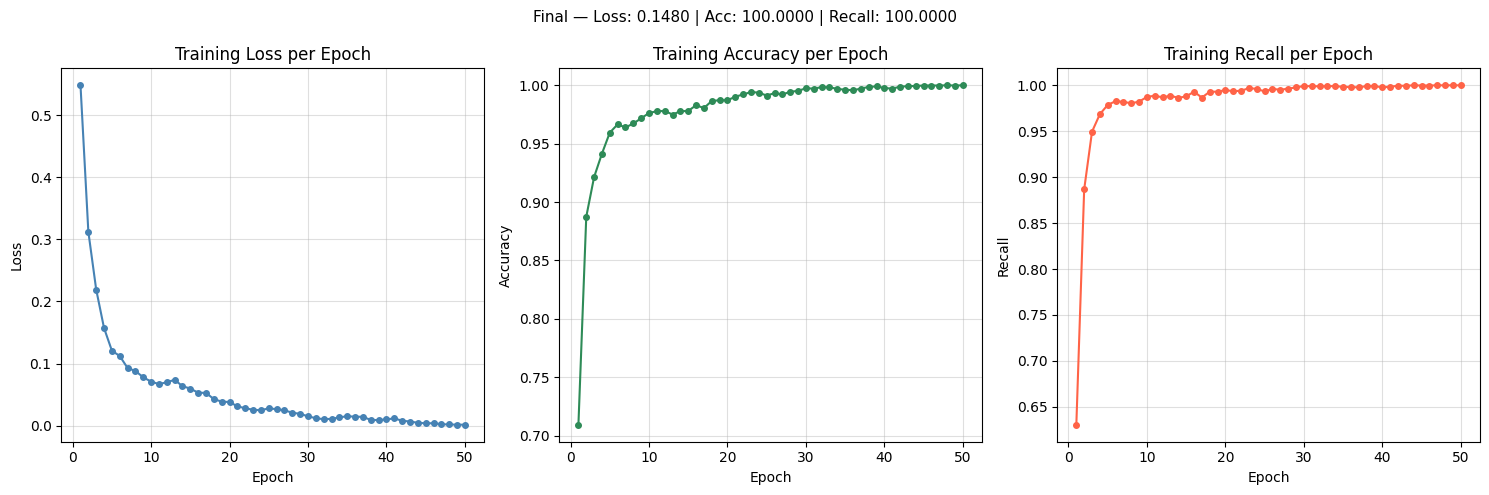

In [6]:
epochs = range(1, len(epoch_losses) + 1)

plt.figure(figsize=(15, 5))
for idx, (data, title, color) in enumerate([
    (epoch_losses,  'Training Loss',     'steelblue'),
    (epoch_accs,    'Training Accuracy', 'seagreen'),
    (epoch_recalls, 'Training Recall',   'tomato'),
]):
    plt.subplot(1, 3, idx + 1)
    plt.plot(epochs, data, marker='o', markersize=4, linestyle='-', color=color)
    plt.title(title + ' per Epoch')
    plt.xlabel('Epoch')
    plt.ylabel(title.split()[-1])
    plt.grid(True, alpha=0.4)

plt.suptitle(
    f'Final — Loss: {epoch_losses[-1]*100:.4f} | '
    f'Acc: {epoch_accs[-1]*100:.4f} | Recall: {epoch_recalls[-1]*100:.4f}',
    fontsize=11
)
plt.tight_layout()
plt.show()

## Cell 7 — Test-Set Evaluation

After training, the model is evaluated on the **held-out test set** (624 images it has never seen).  
We compute four complementary metrics:

| Metric | Formula | What it measures |
|---|---|---|
| **Accuracy** | (TP+TN) / N | Overall correct classifications |
| **Recall** (Sensitivity) | TP / (TP+FN) | How many pneumonia cases are caught — most important clinically |
| **Precision** | TP / (TP+FP) | Of predicted positives, how many are truly positive |
| **F1 Score** | 2·P·R / (P+R) | Harmonic mean of Precision & Recall |

We also collect the raw **confusion matrix** for the visualisation cell below.  
> **Note:** `model.eval()` disables Dropout and switches BatchNorm to inference mode. `torch.no_grad()` suppresses gradient tracking, saving memory and speeding up inference.

In [7]:
model.eval()

all_preds  = []
all_labels = []

with torch.no_grad():
    for imgs, labels in test_loader:
        imgs   = imgs.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        with torch.amp.autocast('cuda'):
            logits = model(imgs).squeeze(1)   # shape: (B,)

        preds = torch.round(torch.sigmoid(logits)).long()
        all_preds.append(preds.cpu())
        all_labels.append(labels.cpu())

all_preds  = torch.cat(all_preds)
all_labels = torch.cat(all_labels)

# -- Metrics --
TP = ((all_preds == 1) & (all_labels == 1)).sum().item()
TN = ((all_preds == 0) & (all_labels == 0)).sum().item()
FP = ((all_preds == 1) & (all_labels == 0)).sum().item()
FN = ((all_preds == 0) & (all_labels == 1)).sum().item()
N  = len(all_labels)

accuracy  = (TP + TN) / N
recall    = TP / (TP + FN + 1e-8)
precision = TP / (TP + FP + 1e-8)
f1        = 2 * precision * recall / (precision + recall + 1e-8)

# Confusion matrix as a 2x2 list  [[TN, FP], [FN, TP]]
conf_matrix = [[TN, FP], [FN, TP]]

# Class names from the dataset folder order
class_names = test_loader.dataset.classes   # ['NORMAL', 'PNEUMONIA']

print(f'Test samples : {N}')
print(f'Accuracy     : {accuracy*100:.4f}  ({TP+TN}/{N} correct)')
print(f'Recall       : {recall*100:.4f}  ({TP} / {TP+FN} pneumonia caught)')
print(f'Precision    : {precision*100:.4f}')
print(f'F1 Score     : {f1*100:.4f}')
print()
print('Confusion matrix:')
print(f'                Pred NORMAL  Pred PNEUMONIA')
print(f'True NORMAL        {TN:>4}          {FP:>4}')
print(f'True PNEUMONIA     {FN:>4}          {TP:>4}')


Test samples : 624
Accuracy     : 85.0962  (531/624 correct)
Recall       : 99.4872  (388 / 390 pneumonia caught)
Precision    : 81.0021
F1 Score     : 89.2980

Confusion matrix:
                Pred NORMAL  Pred PNEUMONIA
True NORMAL         143            91
True PNEUMONIA        2           388


## Cell 8 — Visualise Test Results

Two complementary visualisations:

1. **Confusion-matrix heatmap** — a colour-coded 2×2 grid showing TP / TN / FP / FN counts.  
   - Diagonal = correct predictions (ideally large values).  
   - Off-diagonal = errors: **bottom-left (FN)** = missed pneumonia — the most dangerous mistake.

2. **Sample predictions grid** — 16 random test images with ground-truth vs predicted label.  
   - **Green** title → correct prediction.  
   - **Red** title → wrong prediction.

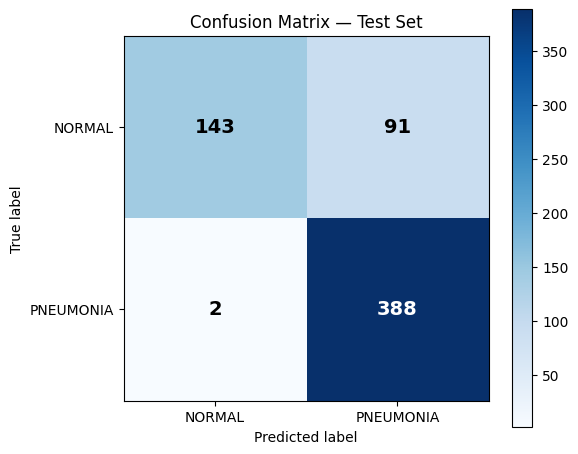

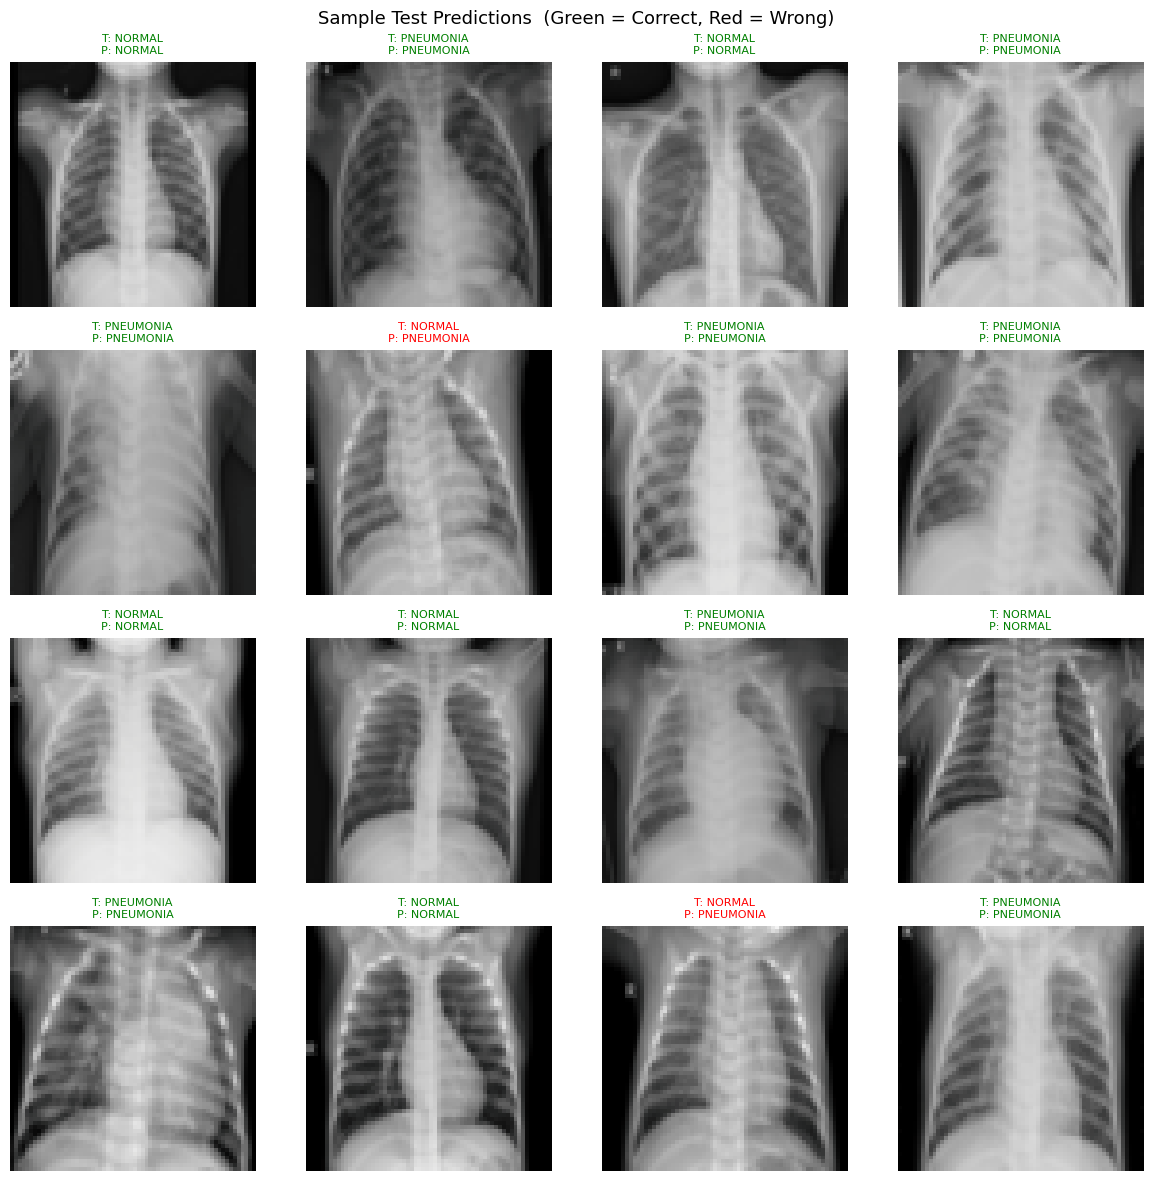

In [8]:
import numpy as np
import itertools

# -- 1. Confusion-matrix heatmap --
fig, ax = plt.subplots(figsize=(6, 5))
cm = np.array(conf_matrix)   # [[TN, FP], [FN, TP]]
im = ax.imshow(cm, interpolation='nearest', cmap='Blues')
plt.colorbar(im, ax=ax)
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(class_names)
ax.set_yticklabels(class_names)
ax.set_xlabel('Predicted label')
ax.set_ylabel('True label')
ax.set_title('Confusion Matrix — Test Set')

thresh = cm.max() / 2.0
for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
    ax.text(j, i, format(cm[i, j], 'd'),
            ha='center', va='center',
            color='white' if cm[i, j] > thresh else 'black',
            fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

# -- 2. Sample predictions grid --
# ImageNet un-normalisation constants
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

model.eval()
sample_imgs, sample_labels = next(iter(test_loader))
with torch.no_grad():
    with torch.amp.autocast('cuda'):
        sample_logits = model(sample_imgs.to(device)).squeeze(1)
sample_preds = torch.round(torch.sigmoid(sample_logits.cpu())).long()

n_show  = 16
indices = torch.randperm(len(sample_imgs))[:n_show]

fig2, grid_axes = plt.subplots(4, 4, figsize=(12, 12))
fig2.suptitle('Sample Test Predictions  (Green = Correct, Red = Wrong)', fontsize=13)

for plot_idx, img_idx in enumerate(indices.tolist()):
    row, col = divmod(plot_idx, 4)
    ax_img   = grid_axes[row][col]

    img = sample_imgs[img_idx] * std + mean   # un-normalise
    img = img.permute(1, 2, 0).clamp(0, 1).numpy()

    true_lbl = class_names[sample_labels[img_idx].item()]
    pred_lbl = class_names[sample_preds[img_idx].item()]
    correct  = sample_labels[img_idx].item() == sample_preds[img_idx].item()
    color    = 'green' if correct else 'red'

    ax_img.imshow(img)
    ax_img.set_title(f'T: {true_lbl}\nP: {pred_lbl}', color=color, fontsize=8)
    ax_img.axis('off')

plt.tight_layout()
plt.show()


## Cell 9 — ROC Curve & Threshold Tuning

The default decision threshold for `BCEWithLogitsLoss` is **0.5** (i.e. `sigmoid(logit) > 0.5 → positive`).  
For a medical classifier we may want to trade precision for recall.  
Three plots are produced:

| Plot | What it shows |
|---|---|
| **ROC Curve** | True-Positive Rate vs False-Positive Rate across all thresholds; AUC near 1.0 means nearly perfect separation |
| **Threshold Sweep** | Accuracy, Recall, Precision, and F1 as a function of threshold |
| **Precision–Recall Curve** | Precision vs Recall tradeoff; useful when class imbalance exists |

The **best threshold** is chosen to maximise the **F1 Score** on the test set.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ── collect raw probabilities on the test set (reuses model / test_loader) ──
model.eval()
all_probs_raw  = []
all_labels_raw = []

with torch.no_grad():
    for imgs, labels in test_loader:
        imgs   = imgs.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        # autocast kept for consistency with training path (fp16 activations)
        with torch.amp.autocast('cuda'):
            logits = model(imgs).squeeze(1)
        # .float() ensures float32 (not float16) before NumPy conversion
        probs = torch.sigmoid(logits).float()
        all_probs_raw.append(probs.cpu())
        all_labels_raw.append(labels.cpu())

# keep float32 throughout — avoids silent upcasting to float64
all_probs_np  = torch.cat(all_probs_raw).numpy().astype(np.float32)
all_labels_np = torch.cat(all_labels_raw).numpy().astype(np.float32)

# ── threshold sweep ──────────────────────────────────────────────────────
thresholds = np.linspace(0, 1, 201, dtype=np.float32)
tprs, fprs, precisions, recalls, f1s, accs = [], [], [], [], [], []

for thr in thresholds:
    preds = (all_probs_np >= thr).astype(np.int8)
    lbl   = all_labels_np.astype(np.int8)
    TP = int(((preds == 1) & (lbl == 1)).sum())
    TN = int(((preds == 0) & (lbl == 0)).sum())
    FP = int(((preds == 1) & (lbl == 0)).sum())
    FN = int(((preds == 0) & (lbl == 1)).sum())
    tprs.append(TP / (TP + FN + 1e-8))
    fprs.append(FP / (FP + TN + 1e-8))
    pr = TP / (TP + FP + 1e-8)
    rc = TP / (TP + FN + 1e-8)
    precisions.append(pr)
    recalls.append(rc)
    f1s.append(2 * pr * rc / (pr + rc + 1e-8))
    accs.append((TP + TN) / len(all_labels_np))

# ── sort by FPR for a clean ROC and correct AUC (handles probability ties) ─
sort_idx   = np.argsort(fprs)
fprs_s     = np.array(fprs)[sort_idx]
tprs_s     = np.array(tprs)[sort_idx]

# AUC via trapezoidal rule on sorted arrays
auc = float(np.trapz(tprs_s, fprs_s))

# ── best threshold = argmax F1 ───────────────────────────────────────────
best_idx       = int(np.argmax(f1s))
best_threshold = float(thresholds[best_idx])
print(f'Best threshold (max F1): {best_threshold:.3f}  '
      f'F1={f1s[best_idx]*100:.2f}%  '
      f'Recall={recalls[best_idx]*100:.2f}%  '
      f'Precision={precisions[best_idx]*100:.2f}%')
print(f'ROC AUC: {auc:.4f}')

# ── sort recall-precision for a smooth PR curve (handles ties) ───────────
pr_sort_idx  = np.argsort(recalls)
recalls_s    = np.array(recalls)[pr_sort_idx]
precisions_s = np.array(precisions)[pr_sort_idx]

# ── Plots ─────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# ROC
ax = axes[0]
ax.plot(fprs_s, tprs_s, color='steelblue', lw=2, label=f'AUC = {auc:.4f}')
ax.plot([0, 1], [0, 1], 'k--', lw=1)
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curve')
ax.legend(loc='lower right')
ax.grid(True, alpha=0.4)

# Threshold sweep
ax = axes[1]
ax.plot(thresholds, accs,       label='Accuracy',  color='steelblue')
ax.plot(thresholds, recalls,    label='Recall',    color='tomato')
ax.plot(thresholds, precisions, label='Precision', color='seagreen')
ax.plot(thresholds, f1s,        label='F1',        color='orange', lw=2)
ax.axvline(best_threshold, color='gray', linestyle='--',
           label=f'Best thr={best_threshold:.2f}')
ax.set_xlabel('Threshold')
ax.set_ylabel('Score')
ax.set_title('Metrics vs Threshold')
ax.legend()
ax.grid(True, alpha=0.4)

# Precision–Recall (sorted by recall for a smooth curve)
ax = axes[2]
ax.plot(recalls_s, precisions_s, color='purple', lw=2)
ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.set_title('Precision–Recall Curve')
ax.grid(True, alpha=0.4)

plt.suptitle('ROC / Threshold Sweep / Precision–Recall', fontsize=12)
plt.tight_layout()
plt.show()

In [ ]:
# ── Apply best threshold and re-evaluate metrics ──────────────────────────
preds_best = (all_probs_np >= best_threshold).astype(np.int8)
lbl_int    = all_labels_np.astype(np.int8)

TP = int(((preds_best == 1) & (lbl_int == 1)).sum())
TN = int(((preds_best == 0) & (lbl_int == 0)).sum())
FP = int(((preds_best == 1) & (lbl_int == 0)).sum())
FN = int(((preds_best == 0) & (lbl_int == 1)).sum())
N  = len(all_labels_np)

accuracy_bt  = (TP + TN) / N
recall_bt    = TP / (TP + FN + 1e-8)
precision_bt = TP / (TP + FP + 1e-8)
f1_bt        = 2 * precision_bt * recall_bt / (precision_bt + recall_bt + 1e-8)

print(f'--- Results with best threshold = {best_threshold:.3f} ---')
print(f'Test samples : {N}')
print(f'Accuracy     : {accuracy_bt*100:.4f}  ({TP+TN}/{N} correct)')
print(f'Recall       : {recall_bt*100:.4f}  ({TP} / {TP+FN} pneumonia caught)')
print(f'Precision    : {precision_bt*100:.4f}')
print(f'F1 Score     : {f1_bt*100:.4f}')
print()
print('Confusion matrix (best threshold):')
print(f'                Pred NORMAL  Pred PNEUMONIA')
print(f'True NORMAL        {TN:>4}          {FP:>4}')
print(f'True PNEUMONIA     {FN:>4}          {TP:>4}')